# 眼底血管分割：小型 U-Net 从零训练，五折交叉验证

只进行训练与验证，不读取测试集，不生成提交文件。

先修改下面的数据路径，再在 Kaggle GPU 环境中运行全部单元格。20 张图按整张图划分为 5 折，每折 16 张训练、4 张验证（数量会随实际数据变化）。血管标签为 1，背景为 0。

模型是轻量 U-Net 基线：通道数 8/16/32/64，3 次下采样、跳跃连接、GroupNorm；不是 Little W-Net 论文网络的逐层复现。所有权重随机初始化，不下载预训练权重。

In [10]:
# ===== 路径配置：运行前首先修改这里 =====
from pathlib import Path

DATA_ROOT = Path('/kaggle/input/competitions/2026task-4/segmentation')  # 改为 Kaggle 挂载的 task4 路径
TRAIN_IMAGE_DIR = DATA_ROOT / 'train' / 'image'
TRAIN_LABEL_DIR = DATA_ROOT / 'train' / 'label'
OUTPUT_DIR = Path('/kaggle/working/task4_small_unet_5fold')

# ===== 训练配置 =====
SEED = 42
N_SPLITS = 5
FOLDS_TO_RUN = [0, 1, 2, 3, 4]  # 五折全部运行；编号为 0~4
IMAGE_SIZE = 512
BASE_CHANNELS = 8
BATCH_SIZE = 4
NUM_WORKERS = 2  # 数据加载遇到问题可设为 0
MAX_EPOCHS = 200
PATIENCE = 40
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
BCE_WEIGHT = 0.5
DICE_WEIGHT = 0.5
PRED_THRESHOLD = 0.5  # 固定阈值，用于验证 Dice；不在验证集上搜索阈值
USE_AMP = True

# 单折如已存在检查点则报错，避免误覆盖；重复实验请修改 OUTPUT_DIR。

## 导入与随机种子
Kaggle 常规 Python 镜像通常已包含以下依赖，无需联网下载。建议开启 GPU。
尽可能固定随机性，但不同硬件/库版本之间不保证逐位一致。

In [11]:
import gc
import json
import math
import random
import time
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
from sklearn.model_selection import KFold
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP_ENABLED = USE_AMP and DEVICE.type == 'cuda'
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('当前使用 CPU，正式五折训练建议在 Kaggle 设置中开启 GPU。')

assert IMAGE_SIZE % 8 == 0
assert N_SPLITS == 5
assert len(set(FOLDS_TO_RUN)) == len(FOLDS_TO_RUN)
assert FOLDS_TO_RUN and all(0 <= f < N_SPLITS for f in FOLDS_TO_RUN)
assert BCE_WEIGHT >= 0 and DICE_WEIGHT >= 0 and BCE_WEIGHT + DICE_WEIGHT > 0

PyTorch: 2.11.0+cu130 | Device: cuda
GPU: Tesla T4


## 配对、检查标签与生成五折
按文件名（去掉扩展名）配对。Pillow 根据文件头解码，支持扩展名与真实格式不同的现有数据。
标签先使用 `>127` 二值化，避免压缩灰度被当成血管；检查原图与标签尺寸是否一致。
所有验证指标均在完整的 512×512 图像上计算，包含图像外围背景，不假设平台采用 DRIVE 的视野掩码规则。

In [12]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.gif', '.bmp'}


def index_images(directory):
    if not directory.is_dir():
        raise FileNotFoundError(f'目录不存在，请修改首个代码单元格：{directory}')
    result = {}
    for path in sorted(directory.iterdir()):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            if path.stem in result:
                raise ValueError(f'文件名重复：{path.stem} in {directory}')
            result[path.stem] = path
    if not result:
        raise ValueError(f'未找到图像：{directory}')
    return result


image_index = index_images(TRAIN_IMAGE_DIR)
label_index = index_images(TRAIN_LABEL_DIR)
if set(image_index) != set(label_index):
    raise ValueError(f'图像和标签不匹配。缺标签：{set(image_index)-set(label_index)}；'
                     f'缺图像：{set(label_index)-set(image_index)}')

ids = sorted(image_index, key=lambda s: (0, int(s)) if s.isdigit() else (1, s))
records = []
for sample_id in ids:
    with Image.open(image_index[sample_id]) as img, Image.open(label_index[sample_id]) as lab:
        if img.size != lab.size:
            raise ValueError(f'{sample_id} 图像/标签尺寸不一致：{img.size} vs {lab.size}')
        mask = np.asarray(lab.convert('L')) > 127
        ratio = float(mask.mean())
        if not 0 < ratio < 1:
            raise ValueError(f'{sample_id} 标签为空或全为前景，请检查标签。')
        records.append({'id': sample_id, 'image_path': str(image_index[sample_id]),
                        'label_path': str(label_index[sample_id]),
                        'width': img.width, 'height': img.height, 'vessel_ratio': ratio})

records = pd.DataFrame(records)
assert len(records) >= N_SPLITS
records['fold'] = -1
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
for fold, (_, val_idx) in enumerate(kf.split(records)):
    records.loc[val_idx, 'fold'] = fold

# 这里只建立目录，不覆盖已有模型。
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for fold in FOLDS_TO_RUN:
    if (OUTPUT_DIR / f'fold_{fold}' / 'best.pt').exists():
        raise FileExistsError(f'fold_{fold}/best.pt 已存在，请更换 OUTPUT_DIR。')
records.to_csv(OUTPUT_DIR / 'fold_assignments.csv', index=False)
CONFIG = {key: globals()[key] for key in [
    'SEED', 'N_SPLITS', 'FOLDS_TO_RUN', 'IMAGE_SIZE', 'BASE_CHANNELS', 'BATCH_SIZE',
    'NUM_WORKERS', 'MAX_EPOCHS', 'PATIENCE', 'LEARNING_RATE', 'WEIGHT_DECAY',
    'BCE_WEIGHT', 'DICE_WEIGHT', 'PRED_THRESHOLD', 'USE_AMP']}
CONFIG.update({'data_root': str(DATA_ROOT), 'output_dir': str(OUTPUT_DIR),
               'model': 'SmallUNet', 'label_threshold': 127, 'pretrained': False,
               'torch_version': str(torch.__version__)})
(OUTPUT_DIR / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
print(records.groupby('fold').agg(n_images=('id', 'count'), mean_vessel_ratio=('vessel_ratio', 'mean')))
display(records.head())

      n_images  mean_vessel_ratio
fold                             
0            4           0.085247
1            4           0.092589
2            4           0.095446
3            4           0.083349
4            4           0.074946


,id,image_path,label_path,width,height,vessel_ratio,fold
0,1,/kaggle/input/competitions/2026task-4/segmenta...,/kaggle/input/competitions/2026task-4/segmenta...,565,584,0.087408,0
1,2,/kaggle/input/competitions/2026task-4/segmenta...,/kaggle/input/competitions/2026task-4/segmenta...,565,584,0.083565,0
2,3,/kaggle/input/competitions/2026task-4/segmenta...,/kaggle/input/competitions/2026task-4/segmenta...,565,584,0.108753,2
3,4,/kaggle/input/competitions/2026task-4/segmenta...,/kaggle/input/competitions/2026task-4/segmenta...,565,584,0.075770,1
4,5,/kaggle/input/competitions/2026task-4/segmenta...,/kaggle/input/competitions/2026task-4/segmenta...,565,584,0.065835,3


## 数据加载与增强
先划分整张图，再建立各折 Dataset。仅训练集使用同步翻转、90 度旋转，以及图像亮度/对比度/颜色扰动。验证集无随机增强。
图像双线性缩放，标签最近邻缩放。输入缩放至 [0,1]，不使用 ImageNet 标准化。

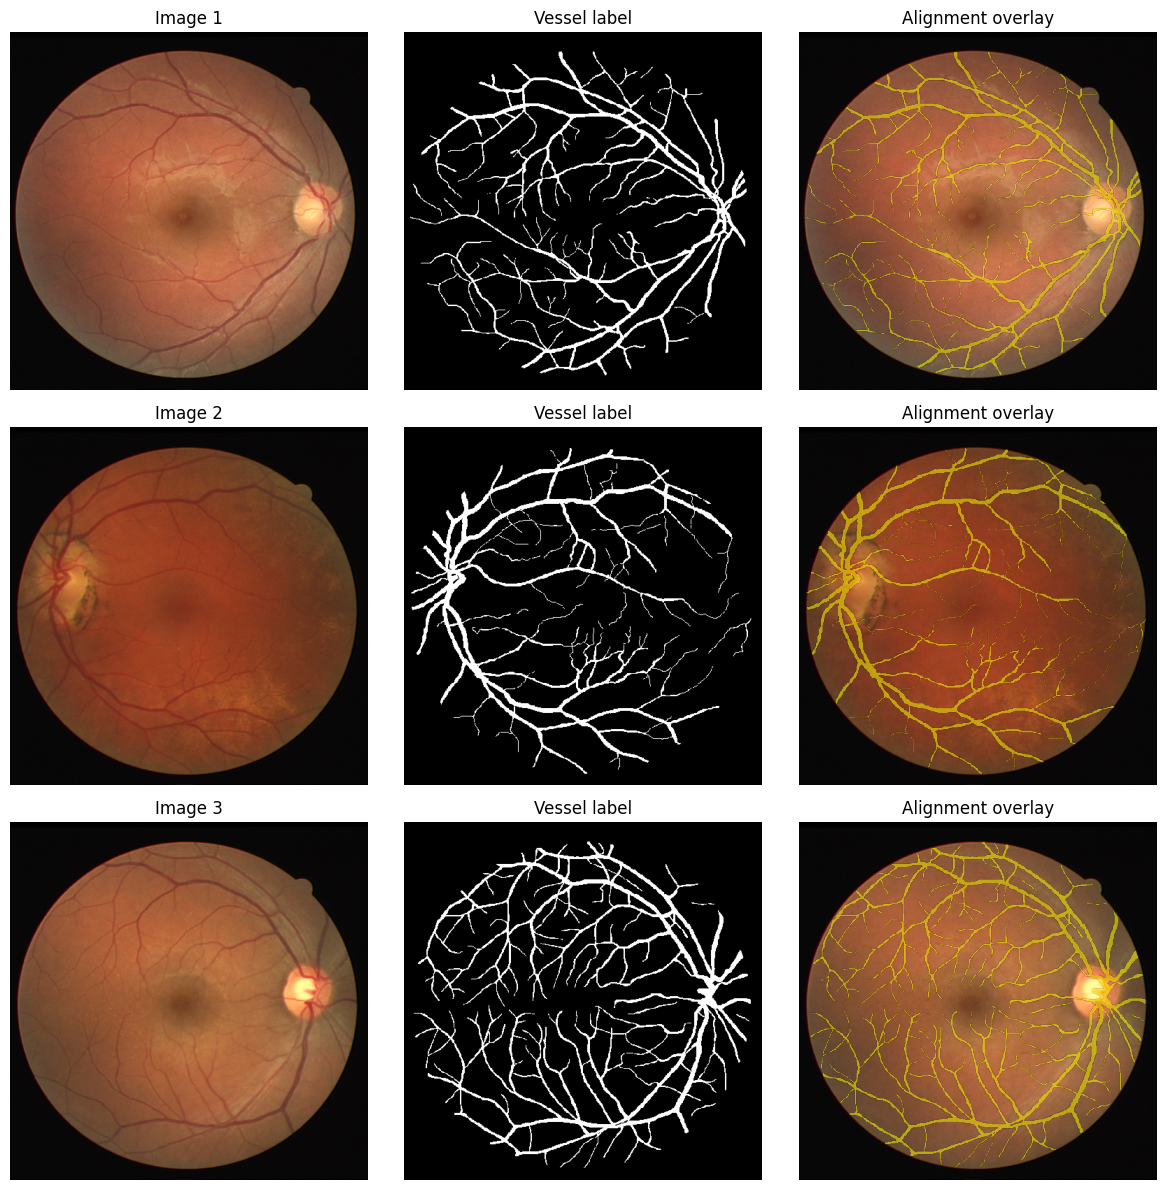

In [13]:
class VesselDataset(Dataset):
    def __init__(self, frame, training=False, image_size=None):
        self.rows = frame.reset_index(drop=True).to_dict('records')
        self.training = training
        self.image_size = IMAGE_SIZE if image_size is None else image_size

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row['image_path']) as source:
            image = source.convert('RGB')
        with Image.open(row['label_path']) as source:
            mask = Image.fromarray((np.asarray(source.convert('L')) > 127).astype(np.uint8) * 255)
        image = image.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        mask = mask.resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
        if self.training:
            if random.random() < 0.5:
                image, mask = ImageOps.mirror(image), ImageOps.mirror(mask)
            if random.random() < 0.5:
                image, mask = ImageOps.flip(image), ImageOps.flip(mask)
            angle = random.choice([0, 90, 180, 270])
            if angle:
                image = image.rotate(angle, resample=Image.Resampling.BILINEAR)
                mask = mask.rotate(angle, resample=Image.Resampling.NEAREST)
            image = ImageEnhance.Brightness(image).enhance(random.uniform(0.85, 1.15))
            image = ImageEnhance.Contrast(image).enhance(random.uniform(0.85, 1.15))
            image = ImageEnhance.Color(image).enhance(random.uniform(0.9, 1.1))
        x = np.asarray(image, dtype=np.float32).transpose(2, 0, 1).copy() / 255.0
        y = (np.asarray(mask) > 127).astype(np.float32)[None].copy()
        return torch.from_numpy(x), torch.from_numpy(y), row['id']


preview_ds = VesselDataset(records.iloc[:3], training=False)
fig, axes = plt.subplots(len(preview_ds), 3, figsize=(12, 4 * len(preview_ds)), squeeze=False)
for i in range(len(preview_ds)):
    x, y, sample_id = preview_ds[i]
    rgb = x.permute(1, 2, 0).numpy()
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f'Image {sample_id}')
    axes[i, 1].imshow(y[0], cmap='gray', vmin=0, vmax=1)
    axes[i, 1].set_title('Vessel label')
    axes[i, 2].imshow(rgb)
    axes[i, 2].imshow(np.ma.masked_where(y[0].numpy() == 0, y[0].numpy()),
                      cmap='autumn', alpha=0.55, vmin=0, vmax=1)
    axes[i, 2].set_title('Alignment overlay')
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()

## 小型 U-Net 与 BCE + Soft Dice
输出为 logits，损失内部处理 Sigmoid；不在损失前做阈值化。
Soft Dice 按每张图分别计算再平均。验证指标为固定阈值 0.5 的逐图 Dice 均值，作为模型选择和早停依据。
同时记录汇总所有验证像素得到的 global Dice；它与逐图均值不是同一指标。

In [14]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class SmallUNet(nn.Module):
    def __init__(self, base=8):
        super().__init__()
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc1 = ConvBlock(3, base)
        self.enc2 = ConvBlock(base, base * 2)
        
        self.bridge = ConvBlock(base * 4, base * 8)
        self.pool = nn.MaxPool2d(2)
        self.dec3 = ConvBlock(base * 8 + base * 4, base * 4)
        self.dec2 = ConvBlock(base * 4 + base * 2, base * 2)
        self.dec1 = ConvBlock(base * 2 + base, base)
        self.head = nn.Conv2d(base, 1, 1)

    @staticmethod
    def up_join(x, skip):
        return torch.cat([F.interpolate(x, size=skip.shape[-2:], mode='bilinear',
                                        align_corners=False), skip], dim=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        x = self.bridge(self.pool(e3))
        x = self.dec3(self.up_join(x, e3))
        x = self.dec2(self.up_join(x, e2))
        x = self.dec1(self.up_join(x, e1))
        return self.head(x)


def initialize_weights(module):
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode='fan_in', nonlinearity='relu')
        if module.bias is not None:
            nn.init.zeros_(module.bias)


class BCEDiceLoss(nn.Module):
    def forward(self, logits, targets):
        # 在 float32 中计算损失，增强混合精度训练时的稳定性。
        logits, targets = logits.float(), targets.float()
        bce = F.binary_cross_entropy_with_logits(logits, targets)
        probs = logits.sigmoid()
        dims = (1, 2, 3)
        intersection = (probs * targets).sum(dims)
        dice = (2 * intersection + 1e-6) / (probs.sum(dims) + targets.sum(dims) + 1e-6)
        dice_loss = 1 - dice.mean()
        loss = BCE_WEIGHT * bce + DICE_WEIGHT * dice_loss
        return loss, bce.detach(), dice_loss.detach()


probe_model = SmallUNet(BASE_CHANNELS)
print(f'可训练参数量：{sum(p.numel() for p in probe_model.parameters() if p.requires_grad):,}')
del probe_model

可训练参数量：122,465


In [15]:
probe_model = SmallUNet(BASE_CHANNELS)
print(probe_model)

SmallUNet(
  (enc3): ConvBlock(
    (layers): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): GroupNorm(4, 32, eps=1e-05, affine=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): GroupNorm(4, 32, eps=1e-05, affine=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc1): ConvBlock(
    (layers): Sequential(
      (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): GroupNorm(4, 8, eps=1e-05, affine=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): GroupNorm(4, 8, eps=1e-05, affine=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (layers): Sequential(
      (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): GroupNorm(4, 16, eps=1e-05, affine=True)
      (2):

## 训练与验证循环
每折重新初始化模型、优化器和学习率调度器。使用 AdamW、余弦学习率调度、梯度裁剪和可选混合精度。
`best.pt` 保存最佳模型、配置、验证分数及该折样本 ID；`history.csv` 保存逐轮日志。
本 Notebook 不实现断点续训；中断后可使用新的输出目录，并通过 `FOLDS_TO_RUN` 运行尚未完成的折。

In [16]:
def autocast_context():
    return torch.amp.autocast('cuda', dtype=torch.float16) if AMP_ENABLED else nullcontext()


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    totals = np.zeros(3, dtype=np.float64)
    count = 0
    for images, targets, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast_context():
            logits = model(images)
            loss, bce, dice_loss = criterion(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError('训练损失出现 NaN/Inf。')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        batch = images.shape[0]
        totals += np.array([loss.item(), bce.item(), dice_loss.item()]) * batch
        count += batch
    return dict(zip(['loss', 'bce', 'dice_loss'], (totals / count).tolist()))


@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    count = 0
    per_image = []
    total_intersection, total_pred, total_target = 0.0, 0.0, 0.0
    for images, targets, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with autocast_context():
            logits = model(images)
            loss, bce, dice_loss = criterion(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError('验证损失出现 NaN/Inf。')
        pred = logits.float().sigmoid() >= PRED_THRESHOLD
        truth = targets > 0.5
        dims = (1, 2, 3)
        intersections = (pred & truth).sum(dims).double()
        pred_sizes = pred.sum(dims).double()
        target_sizes = truth.sum(dims).double()
        dice_values = (2 * intersections + 1e-6) / (pred_sizes + target_sizes + 1e-6)
        for sample_id, dice in zip(sample_ids, dice_values.cpu().tolist()):
            per_image.append({'id': sample_id, 'dice': dice})
        total_intersection += intersections.sum().item()
        total_pred += pred_sizes.sum().item()
        total_target += target_sizes.sum().item()
        batch = images.shape[0]
        totals += np.array([loss.item(), bce.item(), dice_loss.item()]) * batch
        count += batch
    metrics = dict(zip(['loss', 'bce', 'dice_loss'], (totals / count).tolist()))
    metrics['dice'] = float(np.mean([row['dice'] for row in per_image]))
    metrics['global_dice'] = (2 * total_intersection + 1e-6) / (total_pred + total_target + 1e-6)
    return metrics, per_image


def train_fold(fold):
    fold_seed = SEED + fold
    seed_everything(fold_seed)
    fold_dir = OUTPUT_DIR / f'fold_{fold}'
    fold_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = fold_dir / 'best.pt'
    if checkpoint_path.exists():
        raise FileExistsError(f'拒绝覆盖已有模型：{checkpoint_path}')
    train_frame = records[records.fold != fold].copy()
    val_frame = records[records.fold == fold].copy()
    assert set(train_frame.id).isdisjoint(set(val_frame.id))
    generator = torch.Generator().manual_seed(fold_seed)
    train_loader = DataLoader(
        VesselDataset(train_frame, training=True), batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
        worker_init_fn=seed_worker, generator=generator, drop_last=False)
    val_loader = DataLoader(
        VesselDataset(val_frame, training=False), batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
        worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(fold_seed + 1000))
    model = SmallUNet(BASE_CHANNELS).to(DEVICE)
    model.apply(initialize_weights)
    criterion = BCEDiceLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
    best_dice, best_epoch, stale_epochs = -1.0, 0, 0
    best_metrics, best_rows, history = None, None, []
    print(f'Fold {fold}: {len(train_frame)} train / {len(val_frame)} validation')
    progress = tqdm(range(1, MAX_EPOCHS + 1), desc=f'Fold {fold}')
    for epoch in progress:
        started = time.perf_counter()
        lr = optimizer.param_groups[0]['lr']
        train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
        val_metrics, val_rows = validate(model, val_loader, criterion)
        if val_metrics['dice'] > best_dice:
            best_dice, best_epoch, stale_epochs = val_metrics['dice'], epoch, 0
            best_metrics, best_rows = dict(val_metrics), val_rows
            torch.save({
                'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                'fold': fold, 'epoch': epoch, 'seed': fold_seed,
                'val_metrics': best_metrics, 'config': CONFIG,
                'model_kwargs': {'base': BASE_CHANNELS},
                'train_ids': train_frame.id.tolist(), 'val_ids': val_frame.id.tolist(),
            }, checkpoint_path)
            pd.DataFrame(best_rows).assign(fold=fold).to_csv(fold_dir / 'best_val_dice.csv', index=False)
        else:
            stale_epochs += 1
        row = {'epoch': epoch, 'lr': lr, 'seconds': time.perf_counter() - started,
               **{f'train_{k}': v for k, v in train_metrics.items()},
               **{f'val_{k}': v for k, v in val_metrics.items()}}
        history.append(row)
        pd.DataFrame(history).to_csv(fold_dir / 'history.csv', index=False)
        scheduler.step()
        progress.set_postfix(train_loss=f'{train_metrics["loss"]:.4f}',
                             val_dice=f'{val_metrics["dice"]:.4f}', best=f'{best_dice:.4f}')
        if epoch == 1 or epoch % 10 == 0:
            tqdm.write(f'Fold {fold} epoch {epoch}: train loss={train_metrics["loss"]:.4f}, '
                       f'val loss={val_metrics["loss"]:.4f}, val Dice={val_metrics["dice"]:.4f}')
        if stale_epochs >= PATIENCE:
            tqdm.write(f'Fold {fold}: early stop at epoch {epoch}; best epoch={best_epoch}')
            break
    summary = {'fold': fold, 'n_train': len(train_frame), 'n_val': len(val_frame),
               'best_epoch': best_epoch, 'val_dice': best_dice,
               'val_global_dice': best_metrics['global_dice'],
               'val_loss': best_metrics['loss'], 'checkpoint': str(checkpoint_path)}
    (fold_dir / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    del model, optimizer, scheduler, scaler, train_loader, val_loader
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary, pd.DataFrame(best_rows).assign(fold=fold)

## 执行五折训练
运行此单元格会开始训练。每个验证图像仅在它所属折中用于验证。
此处汇报的是使用验证集选择最佳轮次的交叉验证成绩，并非独立测试成绩。

In [17]:
fold_summaries = []
validation_tables = []
for fold in FOLDS_TO_RUN:
    summary, per_image = train_fold(fold)
    fold_summaries.append(summary)
    validation_tables.append(per_image)
    pd.DataFrame(fold_summaries).to_csv(OUTPUT_DIR / 'cv_summary.csv', index=False)
    pd.concat(validation_tables, ignore_index=True).to_csv(OUTPUT_DIR / 'cv_per_image_dice.csv', index=False)

summary_df = pd.DataFrame(fold_summaries)
all_val_scores = pd.concat(validation_tables, ignore_index=True)
assert all_val_scores.id.is_unique
if set(FOLDS_TO_RUN) == set(range(N_SPLITS)):
    assert set(all_val_scores.id) == set(records.id)
    print('五折全部完成，所有图像都恰好参与一次验证。')
else:
    print('当前仅完成选定的折，不是完整五折结果。')
display(summary_df)
print(f'折间 Dice 均值：{summary_df.val_dice.mean():.4f}')
if len(summary_df) > 1:
    print(f'折间 Dice 标准差：{summary_df.val_dice.std(ddof=1):.4f}')
print(f'所有已验证图像的 Dice 均值：{all_val_scores.dice.mean():.4f}')
print('模型和日志目录：', OUTPUT_DIR)

Fold 0: 16 train / 4 validation


Fold 0:   0%|          | 0/200 [00:00<?, ?it/s]

Fold 0 epoch 1: train loss=0.8253, val loss=0.7545, val Dice=0.1913
Fold 0 epoch 10: train loss=0.5125, val loss=0.5073, val Dice=0.5157
Fold 0 epoch 20: train loss=0.4015, val loss=0.3934, val Dice=0.7088
Fold 0 epoch 30: train loss=0.3464, val loss=0.3405, val Dice=0.7284
Fold 0 epoch 40: train loss=0.3133, val loss=0.3066, val Dice=0.7391
Fold 0 epoch 50: train loss=0.2866, val loss=0.2827, val Dice=0.7427
Fold 0 epoch 60: train loss=0.2653, val loss=0.2617, val Dice=0.7510
Fold 0 epoch 70: train loss=0.2446, val loss=0.2413, val Dice=0.7537
Fold 0 epoch 80: train loss=0.2338, val loss=0.2334, val Dice=0.7540
Fold 0 epoch 90: train loss=0.2261, val loss=0.2255, val Dice=0.7580
Fold 0 epoch 100: train loss=0.2198, val loss=0.2182, val Dice=0.7622
Fold 0 epoch 110: train loss=0.2157, val loss=0.2135, val Dice=0.7648
Fold 0 epoch 120: train loss=0.2118, val loss=0.2125, val Dice=0.7640
Fold 0 epoch 130: train loss=0.2105, val loss=0.2096, val Dice=0.7659
Fold 0 epoch 140: train loss=0.

Fold 1:   0%|          | 0/200 [00:00<?, ?it/s]

Fold 1 epoch 1: train loss=1.2358, val loss=1.0933, val Dice=0.1697
Fold 1 epoch 10: train loss=0.7755, val loss=0.7647, val Dice=0.0810
Fold 1 epoch 20: train loss=0.7453, val loss=0.7405, val Dice=0.0008
Fold 1 epoch 30: train loss=0.7291, val loss=0.7258, val Dice=0.0001
Fold 1 epoch 40: train loss=0.6940, val loss=0.6853, val Dice=0.4590
Fold 1 epoch 50: train loss=0.6405, val loss=0.6380, val Dice=0.5808
Fold 1 epoch 60: train loss=0.6000, val loss=0.5963, val Dice=0.6383
Fold 1 epoch 70: train loss=0.5661, val loss=0.5637, val Dice=0.6704
Fold 1 epoch 80: train loss=0.5385, val loss=0.5368, val Dice=0.6839
Fold 1 epoch 90: train loss=0.5153, val loss=0.5181, val Dice=0.6807
Fold 1 epoch 100: train loss=0.4954, val loss=0.4998, val Dice=0.6887
Fold 1 epoch 110: train loss=0.4802, val loss=0.4832, val Dice=0.6983
Fold 1 epoch 120: train loss=0.4662, val loss=0.4735, val Dice=0.6966
Fold 1 epoch 130: train loss=0.4560, val loss=0.4621, val Dice=0.7042
Fold 1 epoch 140: train loss=0.

Fold 2:   0%|          | 0/200 [00:00<?, ?it/s]

... (3 outputs left out)

Fold 4:   0%|          | 0/200 [00:00<?, ?it/s]

Fold 4 epoch 1: train loss=0.5902, val loss=0.5668, val Dice=0.1412
Fold 4 epoch 10: train loss=0.4198, val loss=0.4276, val Dice=0.6808
Fold 4 epoch 20: train loss=0.3628, val loss=0.3683, val Dice=0.7154
Fold 4 epoch 30: train loss=0.3195, val loss=0.3264, val Dice=0.7234
Fold 4 epoch 40: train loss=0.2875, val loss=0.2922, val Dice=0.7349
Fold 4 epoch 50: train loss=0.2642, val loss=0.2657, val Dice=0.7446
Fold 4 epoch 60: train loss=0.2460, val loss=0.2446, val Dice=0.7553
Fold 4 epoch 70: train loss=0.2338, val loss=0.2296, val Dice=0.7617
Fold 4 epoch 80: train loss=0.2223, val loss=0.2226, val Dice=0.7615
Fold 4 epoch 90: train loss=0.2175, val loss=0.2150, val Dice=0.7640
Fold 4 epoch 100: train loss=0.2096, val loss=0.2098, val Dice=0.7654
Fold 4 epoch 110: train loss=0.2057, val loss=0.2047, val Dice=0.7688
Fold 4 epoch 120: train loss=0.2005, val loss=0.1994, val Dice=0.7731
Fold 4 epoch 130: train loss=0.1985, val loss=0.1994, val Dice=0.7715
Fold 4 epoch 140: train loss=0.

,fold,n_train,n_val,best_epoch,val_dice,val_global_dice,val_loss,checkpoint
0,0,16,4,162,0.769877,0.769893,0.204447,/kaggle/working/task4_small_unet_5fold/fold_0/...
1,1,16,4,146,0.710105,0.707452,0.450330,/kaggle/working/task4_small_unet_5fold/fold_1/...
2,2,16,4,146,0.760575,0.761179,0.205500,/kaggle/working/task4_small_unet_5fold/fold_2/...
3,3,16,4,171,0.764579,0.766695,0.209239,/kaggle/working/task4_small_unet_5fold/fold_3/...
4,4,16,4,143,0.776802,0.777563,0.194113,/kaggle/working/task4_small_unet_5fold/fold_4/...


折间 Dice 均值：0.7564
折间 Dice 标准差：0.0266
所有已验证图像的 Dice 均值：0.7564
模型和日志目录： /kaggle/working/task4_small_unet_5fold


## 查看训练曲线
最佳模型保存在各折的 `best.pt`，其中 `model_state_dict` 是模型参数。保留 `config.json` 和 `fold_assignments.csv`，以便后续使用相同结构与数据划分。
没有测试集预测、RLE 编码或全量重训代码。

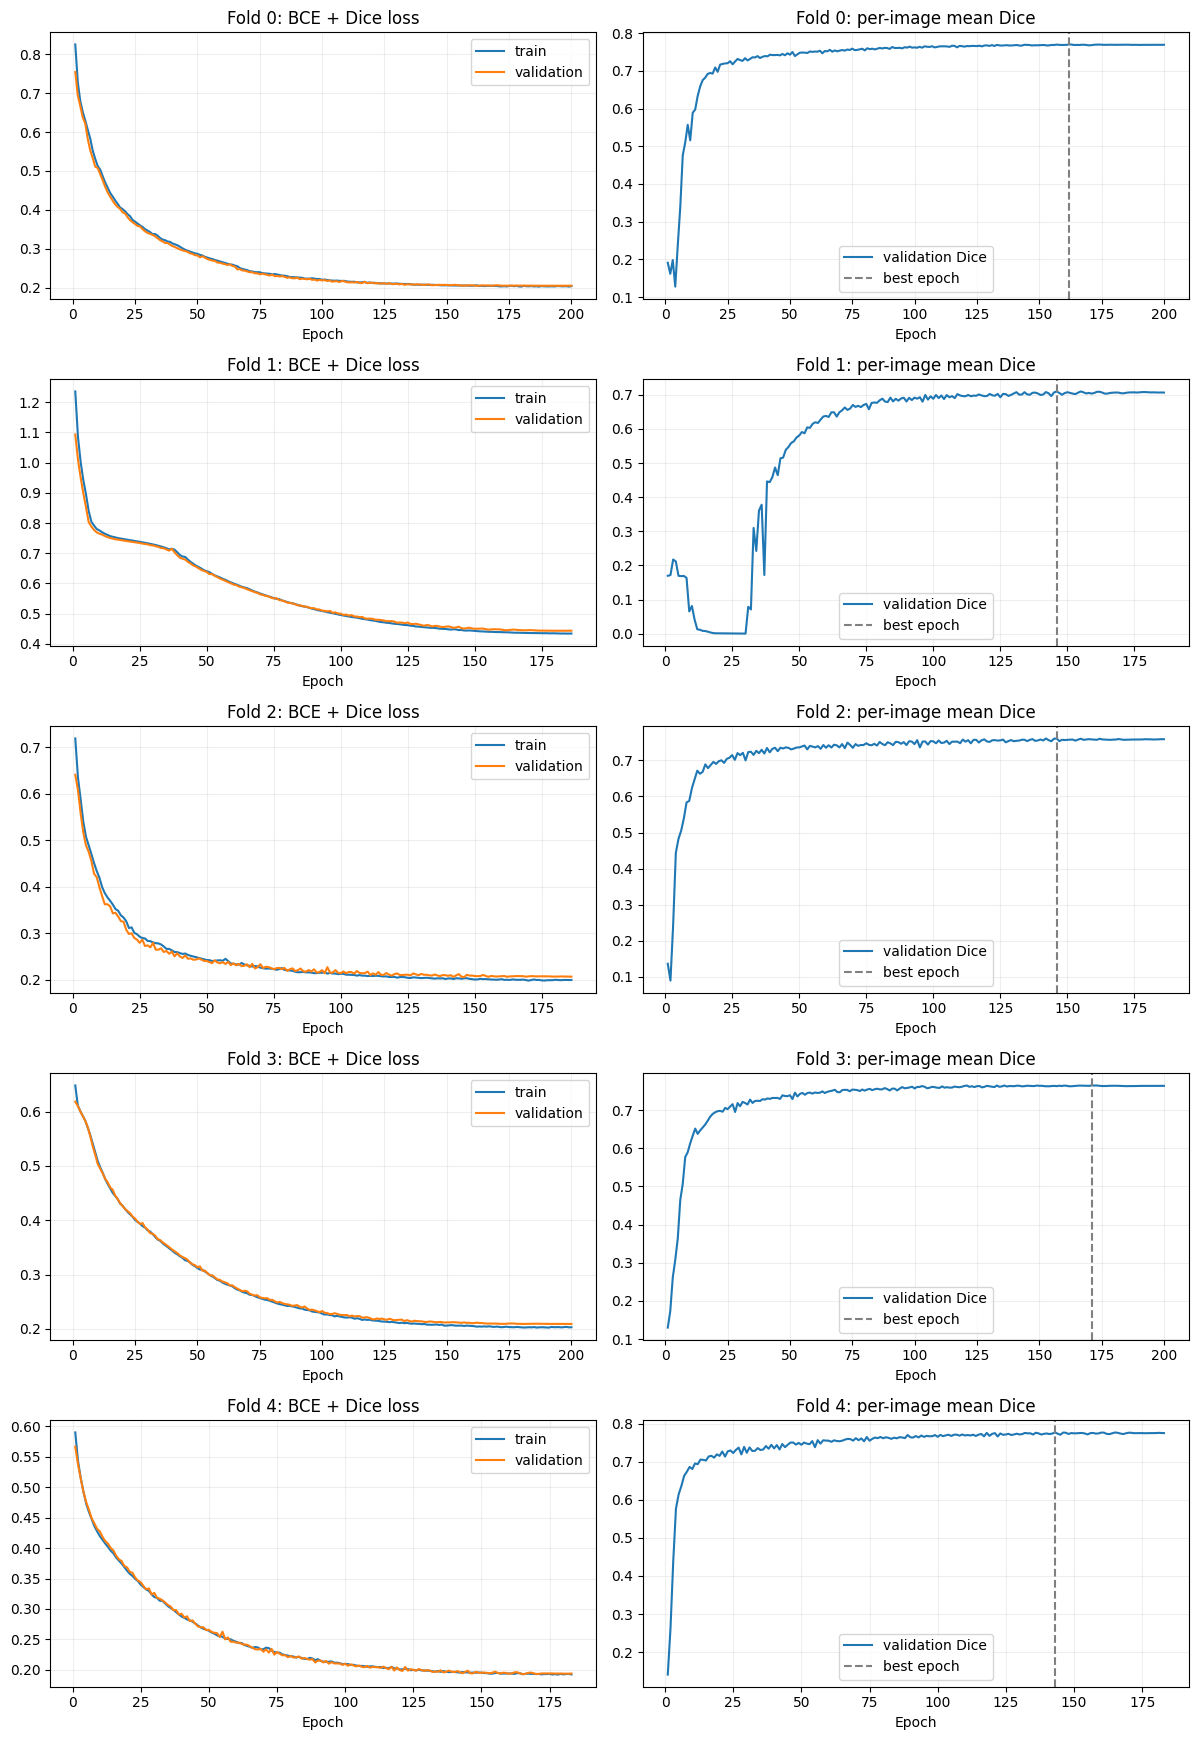

In [24]:
fig, axes = plt.subplots(len(FOLDS_TO_RUN), 2, figsize=(12, 3.5 * len(FOLDS_TO_RUN)), squeeze=False)
for row_index, fold in enumerate(FOLDS_TO_RUN):
    history = pd.read_csv(OUTPUT_DIR / f'fold_{fold}' / 'history.csv')
    axes[row_index, 0].plot(history.epoch, history.train_loss, label='train')
    axes[row_index, 0].plot(history.epoch, history.val_loss, label='validation')
    axes[row_index, 0].set_title(f'Fold {fold}: BCE + Dice loss')
    axes[row_index, 1].plot(history.epoch, history.val_dice, label='validation Dice')
    best_epoch = int(summary_df.loc[summary_df.fold == fold, 'best_epoch'].iloc[0])
    axes[row_index, 1].axvline(best_epoch, linestyle='--', color='gray', label='best epoch')
    axes[row_index, 1].set_title(f'Fold {fold}: per-image mean Dice')
    for ax in axes[row_index]:
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 第 1 折验证诊断

这里的第 1 折指 `fold = 1`。本次训练中它验证了 ID 为 4、6、9、12 的图像。
诊断使用原来的划分表和该折的最佳权重，按 checkpoint 中的输入尺寸和阈值复现验证，并按 Dice 从低到高显示结果。

**已有训练结果时**，在开头设置 `DATA_ROOT` 和 `CV_RESULTS_DIR`，然后只运行以下代码单元格，按顺序执行。

1. 路径与训练配置（以 `from pathlib import Path` 开头的配置单元格）
2. 导入与随机种子（以 `import gc` 开头）
3. 数据集定义（以 `class VesselDataset` 开头）
4. 模型与损失定义（以 `class ConvBlock` 开头）
5. 本节下方的诊断单元格

新 Kaggle 会话需要挂载训练数据，以及包含 `fold_assignments.csv` 和 `fold_1/best.pt` 的训练结果。
图中绿色为正确分割，红色为误检（FP），蓝色为漏检（FN）。每张图还会输出 Dice、精确率、召回率和像素计数。

Fold 1 | epoch 146 | size 512 | threshold 0.5
本次复算平均 Dice：0.7101；训练时记录：0.7101
设备或混合精度设置不同可能带来轻微分数差异。


,id,dice,precision,recall,tp,fp,fn
0,12,0.5819,0.5653,0.5996,15365,11816,10260
1,4,0.7311,0.6440,0.8455,16838,9309,3077
2,9,0.7593,0.7443,0.7748,16401,5634,4766
3,6,0.7681,0.8610,0.6932,20893,3373,9245


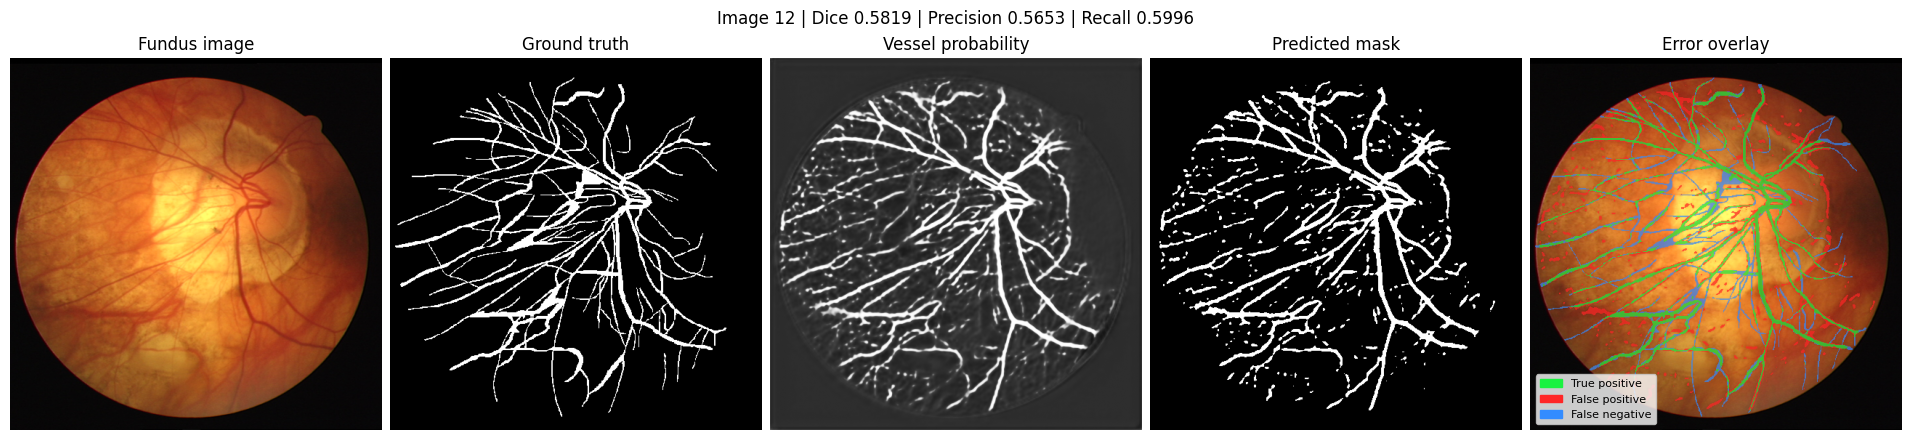

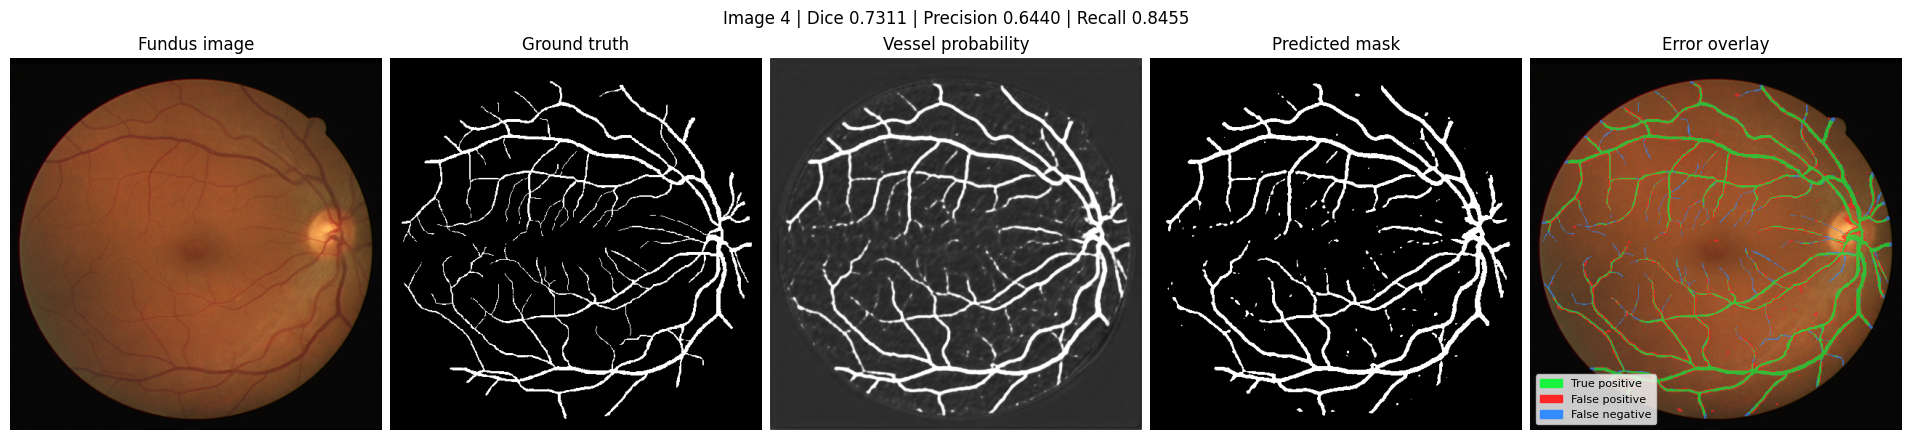

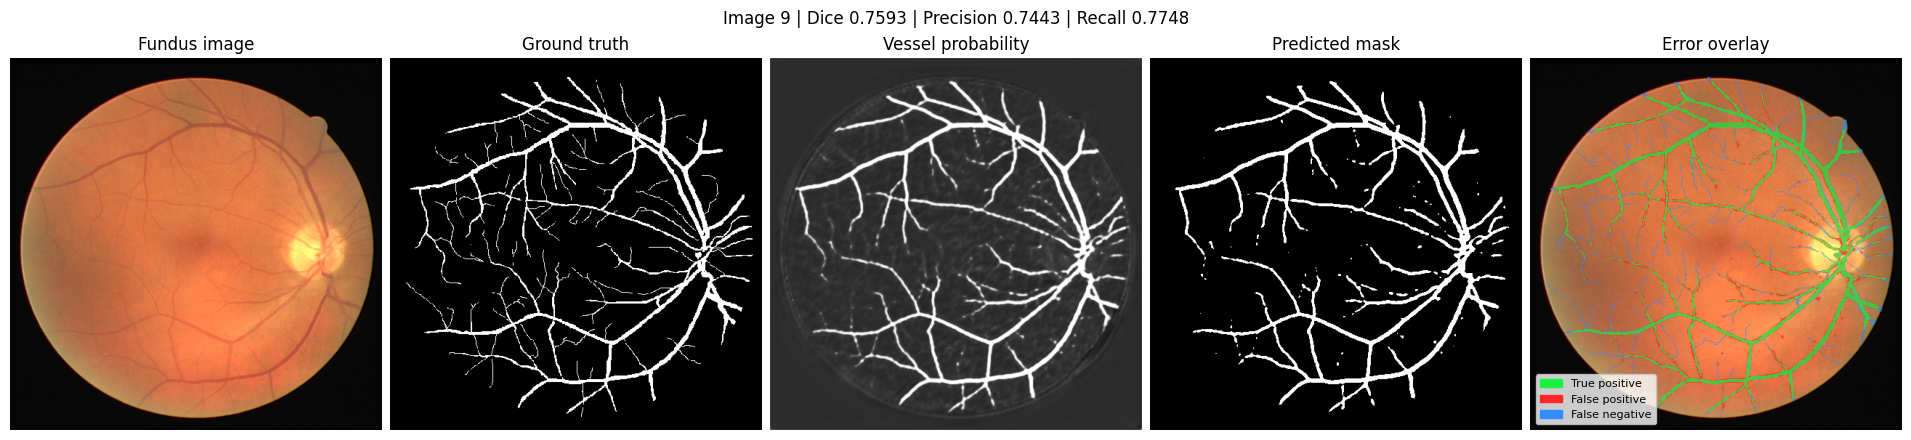

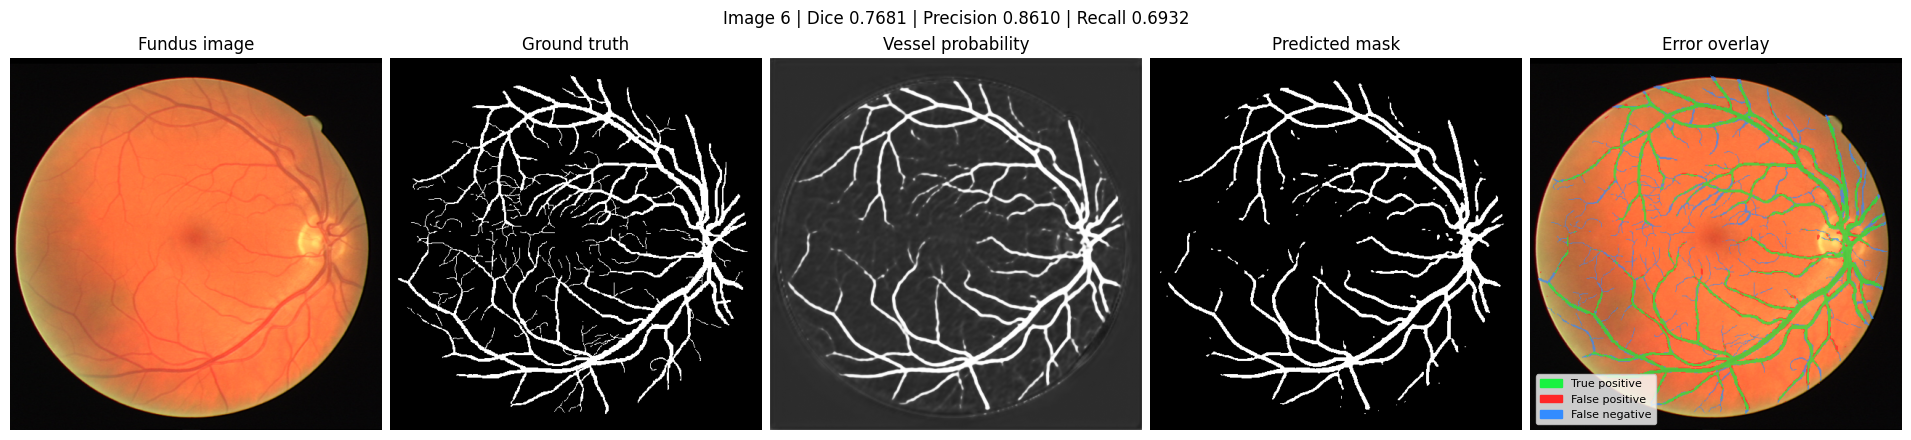

诊断结果目录： /kaggle/working/task4_fold1_diagnostics


In [19]:
from matplotlib.patches import Patch

# ===== 第 1 折验证集结果可视化 =====
# 在本次训练会话内可直接使用 OUTPUT_DIR。
# 新开 Kaggle Notebook 时，将 CV_RESULTS_DIR 改为已挂载的训练输出目录。
CV_RESULTS_DIR = OUTPUT_DIR
FOLD1_CHECKPOINT = CV_RESULTS_DIR / 'fold_1' / 'best.pt'
CV_ASSIGNMENTS_CSV = CV_RESULTS_DIR / 'fold_assignments.csv'
DIAGNOSTIC_OUTPUT_DIR = Path('/kaggle/working/task4_fold1_diagnostics')

for required_path in (FOLD1_CHECKPOINT, CV_ASSIGNMENTS_CSV):
    if not required_path.is_file():
        raise FileNotFoundError(f'找不到 {required_path}，请检查开头的 CV_RESULTS_DIR。')

fold_number = 1
checkpoint = torch.load(FOLD1_CHECKPOINT, map_location='cpu', weights_only=True)
if checkpoint['fold'] != fold_number:
    raise ValueError(f'需要 fold={fold_number} 的权重，实际是 fold={checkpoint["fold"]}。')

assignment = pd.read_csv(CV_ASSIGNMENTS_CSV, dtype={'id': str})
fold1_frame = assignment.loc[assignment['fold'] == fold_number].copy()
if fold1_frame.empty or not fold1_frame['id'].is_unique:
    raise ValueError('划分表中该折没有验证样本，或存在重复 ID。')
if set(fold1_frame['id']) != set(checkpoint['val_ids']):
    raise ValueError('划分表中的验证 ID 与权重记录不一致，请使用同一次训练的文件。')

# 划分表中的绝对路径可能来自旧会话，只复用文件名。
for column, directory in [('image_path', TRAIN_IMAGE_DIR), ('label_path', TRAIN_LABEL_DIR)]:
    fold1_frame[column] = fold1_frame[column].map(lambda p: str(directory / Path(p).name))
    for file_path in fold1_frame[column]:
        if not Path(file_path).is_file():
            raise FileNotFoundError(f'找不到 {file_path}，请检查开头的 DATA_ROOT。')

model_config = checkpoint['config']
if model_config['label_threshold'] != 127:
    raise ValueError('该权重的标签阈值与 VesselDataset 的读取规则不一致。')
image_size = int(model_config['IMAGE_SIZE'])
threshold = float(model_config['PRED_THRESHOLD'])
diagnostic_amp = bool(model_config['USE_AMP']) and DEVICE.type == 'cuda'
fold1_ds = VesselDataset(fold1_frame, training=False, image_size=image_size)

fold1_model = SmallUNet(**checkpoint['model_kwargs']).to(DEVICE)
fold1_model.load_state_dict(checkpoint['model_state_dict'], strict=True)
fold1_model.eval()
DIAGNOSTIC_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

records_fold1 = []
previews_fold1 = {}
with torch.inference_mode():
    for index in range(len(fold1_ds)):
        x, y, sample_id = fold1_ds[index]
        amp_context = torch.amp.autocast('cuda', dtype=torch.float16) if diagnostic_amp else nullcontext()
        with amp_context:
            logits = fold1_model(x.unsqueeze(0).to(DEVICE))
        prob = logits.float().sigmoid()[0, 0].cpu().numpy()
        pred = prob >= threshold
        truth = y[0].numpy() > 0.5
        true_positive = pred & truth
        false_positive = pred & ~truth
        false_negative = ~pred & truth
        tp, fp, fn = (int(mask.sum()) for mask in (true_positive, false_positive, false_negative))
        records_fold1.append({
            'id': sample_id,
            'dice': (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6),
            'precision': tp / (tp + fp) if tp + fp else 0.0,
            'recall': tp / (tp + fn) if tp + fn else 0.0,
            'tp': tp, 'fp': fp, 'fn': fn,
        })
        rgb = x.permute(1, 2, 0).numpy()
        overlay = rgb.copy()
        for mask, color in [(true_positive, (0.1, 0.95, 0.25)),
                            (false_positive, (1.0, 0.15, 0.15)),
                            (false_negative, (0.2, 0.55, 1.0))]:
            overlay[mask] = 0.3 * rgb[mask] + 0.7 * np.asarray(color)
        previews_fold1[sample_id] = (rgb, truth, prob, pred, overlay)

diagnostics = pd.DataFrame(records_fold1).sort_values('dice').reset_index(drop=True)
diagnostics.to_csv(DIAGNOSTIC_OUTPUT_DIR / 'fold_1_per_image_metrics.csv', index=False)
print(f'Fold {fold_number} | epoch {checkpoint["epoch"]} | size {image_size} | threshold {threshold:g}')
print(f'本次复算平均 Dice：{diagnostics.dice.mean():.4f}；训练时记录：{checkpoint["val_metrics"]["dice"]:.4f}')
print('设备或混合精度设置不同可能带来轻微分数差异。')
display(diagnostics.round(4))

legend = [Patch(color=(0.1, 0.95, 0.25), label='True positive'),
          Patch(color=(1.0, 0.15, 0.15), label='False positive'),
          Patch(color=(0.2, 0.55, 1.0), label='False negative')]
for row in diagnostics.itertuples(index=False):
    fig, axes = plt.subplots(1, 5, figsize=(19, 4.5), layout='constrained')
    for axis, panel, title in zip(
        axes, previews_fold1[row.id],
        ['Fundus image', 'Ground truth', 'Vessel probability', 'Predicted mask', 'Error overlay']
    ):
        if panel.ndim == 2:
            axis.imshow(panel, cmap='gray', vmin=0, vmax=1)
        else:
            axis.imshow(panel)
        axis.set_title(title)
        axis.axis('off')
    axes[-1].legend(handles=legend, loc='lower left', fontsize=8)
    fig.suptitle(f'Image {row.id} | Dice {row.dice:.4f} | Precision {row.precision:.4f} | Recall {row.recall:.4f}')
    fig.savefig(DIAGNOSTIC_OUTPUT_DIR / f'fold_1_image_{row.id}.png', dpi=150)
    plt.show()
    plt.close(fig)

print('诊断结果目录：', DIAGNOSTIC_OUTPUT_DIR)

## 五折验证阈值扫描

用每折的 `best.pt` 推理该折的验证图像。每张图只用一个模型推理一次，随后在其概率图上扫描 0.30 到 0.70，步长 0.01。以 0.50 为对照，按 20 张图的平均 Dice 选出候选阈值，同时比较 FP、FN 和细血管召回率。

**在 Kaggle 用已有权重运行时**，将首个代码单元格的 `DATA_ROOT` 指向训练数据目录，`CV_RESULTS_DIR` 指向包含 `fold_assignments.csv` 和 `fold_0/best.pt` 到 `fold_4/best.pt` 的训练结果目录。按顺序运行配置、导入（`import gc`）、数据集定义（`class VesselDataset`）、模型定义（`class ConvBlock`）和本节代码即可，无需执行任何训练或第 1 折叠加图单元格。

细血管召回率是一个诊断指标。先提取标签骨架，挑出到最近背景像素距离不超过 `THIN_CENTERLINE_MAX_RADIUS` 的中心线点，再统计其中有多少被预测为血管。它衡量细分支中心线的检出情况，按验证图像计算后取平均。阈值扫描的分数来自这批验证图，最佳阈值的收益应在独立数据上确认。

输出目录 `SWEEP_OUTPUT_DIR` 下会生成逐阈值汇总、逐折与逐图指标、相对 0.50 的对比和曲线图。

Fold 0 | epoch 162 | validation IDs: 1, 2, 16, 18
Fold 1 | epoch 146 | validation IDs: 4, 6, 9, 12
Fold 2 | epoch 146 | validation IDs: 3, 14, 17, 19
Fold 3 | epoch 171 | validation IDs: 5, 10, 13, 20
Fold 4 | epoch 143 | validation IDs: 7, 8, 11, 15
平均 Dice：0.50 阈值 0.7564 | 最佳候选 0.51 阈值 0.7565 (+0.0001)
细血管中心线召回率：0.5855 → 0.5832
误检 FP：103,230 → 101,475 | 漏检 FN：115,461 → 116,449


,threshold,n_images,mean_dice,mean_precision,mean_recall,mean_thin_centerline_recall,tp,fp,fn,thin_tp,thin_fn,global_dice,mean_dice_delta_vs_050,mean_thin_centerline_recall_delta_vs_050,fp_delta_vs_050,fn_delta_vs_050,thin_fn_delta_vs_050
20,0.50,20,0.7564,0.7692,0.7506,0.5855,337133,103230,115461,66905,48520,0.7551,0.0000,0.0000,0.0,0.0,0.0
21,0.51,20,0.7565,0.7716,0.7485,0.5832,336145,101475,116449,66640,48785,0.7552,0.0001,-0.0023,-1755.0,988.0,265.0


,fold,id,dice_at_050,dice_at_best,dice_delta,thin_centerline_recall_delta,fp_delta,fn_delta
7,1,12,0.5820,0.5826,0.0006,-0.0016,-239,76
12,3,5,0.7034,0.7048,0.0014,-0.0014,-139,32
11,2,19,0.7289,0.7279,-0.0010,-0.0029,-36,54
4,1,4,0.7311,0.7323,0.0012,-0.0031,-155,46
17,4,8,0.7574,0.7575,0.0001,-0.0027,-64,35
6,1,9,0.7593,0.7598,0.0005,-0.0032,-136,66
10,2,17,0.7619,0.7612,-0.0007,-0.0033,-51,55
1,0,2,0.7626,0.7628,0.0002,-0.0030,-80,43
16,4,7,0.7627,0.7631,0.0004,-0.0026,-67,30
3,0,18,0.7652,0.7653,0.0001,-0.0022,-74,43


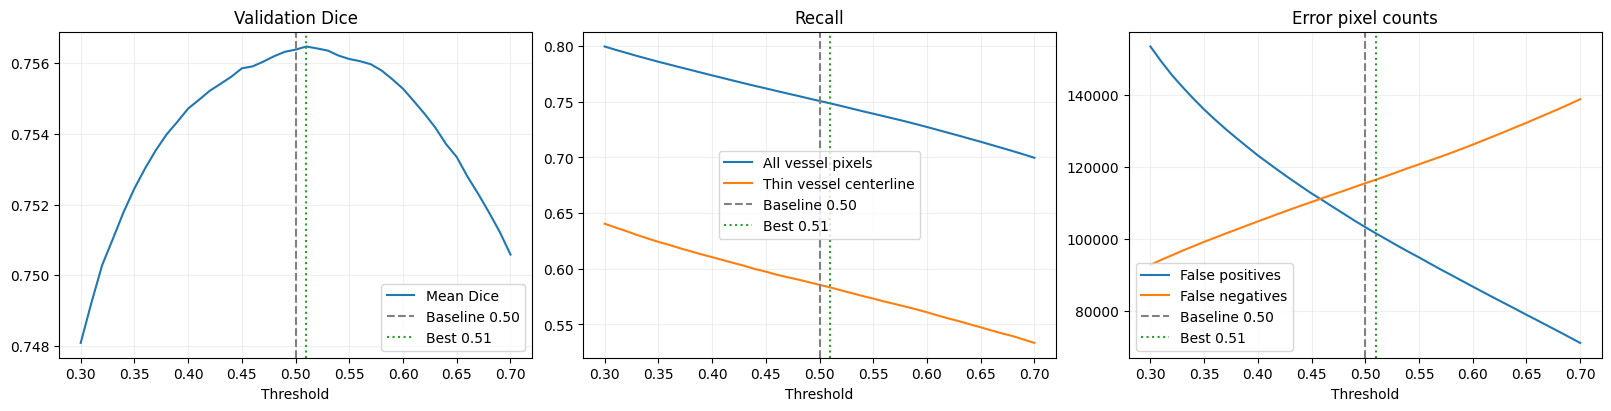

结果目录： /kaggle/working/task4_threshold_sweep


In [20]:
from scipy.ndimage import distance_transform_edt
from skimage.morphology import skeletonize

# ===== 已有权重与验证分析路径 =====
# 在本次训练会话内可直接使用 OUTPUT_DIR。
# 新开 Kaggle Notebook 时，将 CV_RESULTS_DIR 改为已挂载的训练输出目录。
CV_RESULTS_DIR = OUTPUT_DIR
FOLD1_CHECKPOINT = CV_RESULTS_DIR / 'fold_1' / 'best.pt'
CV_ASSIGNMENTS_CSV = CV_RESULTS_DIR / 'fold_assignments.csv'
DIAGNOSTIC_OUTPUT_DIR = Path('/kaggle/working/task4_fold1_diagnostics')
SWEEP_OUTPUT_DIR = Path('/kaggle/working/task4_threshold_sweep')
SWEEP_THRESHOLDS = tuple(i / 100 for i in range(30, 71))
THIN_CENTERLINE_MAX_RADIUS = 2.0  # 在验证尺寸下，以像素为单位

sweep_folds = list(range(N_SPLITS))
checkpoint_paths = {fold: CV_RESULTS_DIR / f'fold_{fold}' / 'best.pt' for fold in sweep_folds}
missing = [p for p in [CV_ASSIGNMENTS_CSV, *checkpoint_paths.values()] if not p.is_file()]
if missing:
    raise FileNotFoundError('请检查开头的 CV_RESULTS_DIR，缺少文件：'
                            + ', '.join(str(p) for p in missing))

sweep_assignment = pd.read_csv(CV_ASSIGNMENTS_CSV, dtype={'id': str})
if (sweep_assignment['id'].isna().any() or not sweep_assignment['id'].is_unique
        or set(sweep_assignment['fold']) != set(sweep_folds)):
    raise ValueError('划分表需包含五折，且每张图恰好分配一次。')

# 用当前 Kaggle 挂载路径读取旧划分表中记录的文件。
for column, directory in [('image_path', TRAIN_IMAGE_DIR), ('label_path', TRAIN_LABEL_DIR)]:
    sweep_assignment[column] = sweep_assignment[column].map(lambda p: str(directory / Path(p).name))
    for file_path in sweep_assignment[column]:
        if not Path(file_path).is_file():
            raise FileNotFoundError(f'找不到 {file_path}，请检查开头的 DATA_ROOT。')


def measure_thresholds(prob, truth, sample_id, fold):
    radius = distance_transform_edt(truth)
    thin_centerline = skeletonize(truth) & (radius <= THIN_CENTERLINE_MAX_RADIUS)
    thin_total = int(thin_centerline.sum())
    true_total = int(truth.sum())
    rows = []
    for threshold in SWEEP_THRESHOLDS:
        pred = prob >= threshold
        tp = int(np.count_nonzero(pred & truth))
        fp = int(np.count_nonzero(pred)) - tp
        fn = true_total - tp
        thin_tp = int(np.count_nonzero(pred & thin_centerline))
        rows.append({
            'fold': fold, 'id': sample_id, 'threshold': threshold,
            'dice': (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6),
            'precision': tp / (tp + fp) if tp + fp else 0.0,
            'recall': tp / true_total if true_total else np.nan,
            'thin_centerline_recall': thin_tp / thin_total if thin_total else np.nan,
            'tp': tp, 'fp': fp, 'fn': fn,
            'thin_tp': thin_tp, 'thin_fn': thin_total - thin_tp,
        })
    return rows


@torch.inference_mode()
def sweep_fold(fold):
    checkpoint = torch.load(checkpoint_paths[fold], map_location='cpu', weights_only=True)
    frame = sweep_assignment.loc[sweep_assignment['fold'] == fold]
    if (checkpoint['fold'] != fold or set(checkpoint['val_ids']) != set(frame['id'])
            or set(checkpoint['train_ids']) != set(sweep_assignment['id']) - set(frame['id'])):
        raise ValueError(f'第 {fold} 折权重与划分表不匹配，请检查训练结果目录。')

    config = checkpoint['config']
    if config['label_threshold'] != 127:
        raise ValueError('权重中的标签阈值与 VesselDataset 的读取规则不一致。')
    dataset = VesselDataset(frame, training=False, image_size=int(config['IMAGE_SIZE']))
    loader = DataLoader(dataset, batch_size=int(config['BATCH_SIZE']), shuffle=False, num_workers=0)
    model = SmallUNet(**checkpoint['model_kwargs']).to(DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'], strict=True)
    model.eval()
    use_amp = bool(config['USE_AMP']) and DEVICE.type == 'cuda'

    rows = []
    for images, targets, sample_ids in loader:
        amp_context = torch.amp.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
        with amp_context:
            logits = model(images.to(DEVICE))
        probs = logits.float().sigmoid()[:, 0].cpu().numpy()
        if not np.isfinite(probs).all():
            raise FloatingPointError(f'第 {fold} 折的概率图出现 NaN 或 Inf。')
        masks = targets[:, 0].numpy() > 0.5
        for prob, truth, sample_id in zip(probs, masks, sample_ids):
            rows.extend(measure_thresholds(prob, truth, sample_id, fold))

    print(f'Fold {fold} | epoch {checkpoint["epoch"]} | validation IDs: {", ".join(frame["id"])}')
    return rows


sweep_rows = []
for fold in sweep_folds:
    sweep_rows.extend(sweep_fold(fold))
per_image_sweep = pd.DataFrame(sweep_rows)
if (per_image_sweep.duplicated(['id', 'threshold']).any()
        or len(per_image_sweep) != len(sweep_assignment) * len(SWEEP_THRESHOLDS)):
    raise RuntimeError('逐图扫描结果未完整覆盖划分表与阈值网格。')


def summarize_sweep(data, group_cols):
    result = data.groupby(group_cols, as_index=False).agg(
        n_images=('id', 'size'),
        mean_dice=('dice', 'mean'),
        mean_precision=('precision', 'mean'),
        mean_recall=('recall', 'mean'),
        mean_thin_centerline_recall=('thin_centerline_recall', 'mean'),
        tp=('tp', 'sum'), fp=('fp', 'sum'), fn=('fn', 'sum'),
        thin_tp=('thin_tp', 'sum'), thin_fn=('thin_fn', 'sum'),
    )
    result['global_dice'] = ((2 * result['tp'] + 1e-6)
                             / (2 * result['tp'] + result['fp'] + result['fn'] + 1e-6))
    return result


per_fold_sweep = summarize_sweep(per_image_sweep, ['fold', 'threshold'])
sweep_summary = summarize_sweep(per_image_sweep, ['threshold'])
baseline_threshold = 0.50
baseline = sweep_summary.loc[sweep_summary['threshold'].eq(baseline_threshold)].iloc[0]
# Dice 相同时选择离 0.50 最近的阈值，再取较小者。
ranked = sweep_summary.assign(distance_to_baseline=(sweep_summary['threshold'] - baseline_threshold).abs())
best = ranked.sort_values(
    ['mean_dice', 'distance_to_baseline', 'threshold'], ascending=[False, True, True]).iloc[0]
best_threshold = float(best['threshold'])

for metric in ['mean_dice', 'mean_thin_centerline_recall', 'fp', 'fn', 'thin_fn']:
    sweep_summary[f'{metric}_delta_vs_050'] = sweep_summary[metric] - baseline[metric]

comparison_metrics = ['dice', 'precision', 'recall', 'thin_centerline_recall', 'fp', 'fn', 'thin_fn']
comparison = (
    per_image_sweep.loc[per_image_sweep['threshold'].eq(baseline_threshold),
                        ['fold', 'id', *comparison_metrics]]
    .merge(per_image_sweep.loc[per_image_sweep['threshold'].eq(best_threshold),
                               ['fold', 'id', *comparison_metrics]],
           on=['fold', 'id'], suffixes=('_at_050', '_at_best'), validate='one_to_one')
)
for metric in comparison_metrics:
    comparison[f'{metric}_delta'] = comparison[f'{metric}_at_best'] - comparison[f'{metric}_at_050']

SWEEP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sweep_summary.to_csv(SWEEP_OUTPUT_DIR / 'threshold_summary.csv', index=False)
per_fold_sweep.to_csv(SWEEP_OUTPUT_DIR / 'threshold_per_fold.csv', index=False)
per_image_sweep.to_csv(SWEEP_OUTPUT_DIR / 'threshold_per_image.csv', index=False)
comparison.to_csv(SWEEP_OUTPUT_DIR / 'per_image_best_vs_050.csv', index=False)

print(f'平均 Dice：0.50 阈值 {baseline["mean_dice"]:.4f} | '
      f'最佳候选 {best_threshold:.2f} 阈值 {best["mean_dice"]:.4f} '
      f'({best["mean_dice"] - baseline["mean_dice"]:+.4f})')
print(f'细血管中心线召回率：{baseline["mean_thin_centerline_recall"]:.4f} '
      f'→ {best["mean_thin_centerline_recall"]:.4f}')
print(f'误检 FP：{int(baseline["fp"]):,} → {int(best["fp"]):,} | '
      f'漏检 FN：{int(baseline["fn"]):,} → {int(best["fn"]):,}')
display(sweep_summary.loc[sweep_summary['threshold'].isin([baseline_threshold, best_threshold])].round(4))
display(comparison[['fold', 'id', 'dice_at_050', 'dice_at_best', 'dice_delta',
                    'thin_centerline_recall_delta', 'fp_delta', 'fn_delta']]
        .sort_values('dice_at_050').round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout='constrained')
axes[0].plot(sweep_summary['threshold'], sweep_summary['mean_dice'], label='Mean Dice')
axes[1].plot(sweep_summary['threshold'], sweep_summary['mean_recall'], label='All vessel pixels')
axes[1].plot(sweep_summary['threshold'], sweep_summary['mean_thin_centerline_recall'],
             label='Thin vessel centerline')
axes[2].plot(sweep_summary['threshold'], sweep_summary['fp'], label='False positives')
axes[2].plot(sweep_summary['threshold'], sweep_summary['fn'], label='False negatives')
for ax, title in zip(axes, ['Validation Dice', 'Recall', 'Error pixel counts']):
    ax.axvline(baseline_threshold, color='gray', linestyle='--', label='Baseline 0.50')
    if best_threshold != baseline_threshold:
        ax.axvline(best_threshold, color='tab:green', linestyle=':', label=f'Best {best_threshold:.2f}')
    ax.set(xlabel='Threshold', title=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.savefig(SWEEP_OUTPUT_DIR / 'threshold_curves.png', dpi=150)
plt.show()
plt.close(fig)
print('结果目录：', SWEEP_OUTPUT_DIR)

## 全量训练与测试集提交

默认取五折最佳轮次的中位数。你最近报告的轮次为 184、179、100、160、161，均值为 156.8，中位数为 161。
中位数受较早达到最佳结果的单折影响较小。这里把它作为全量训练的轮数估计，实际数值会从当前五折权重的 `epoch` 字段读取。
20 张图每轮的优化步数比单折 16 张图更多，因此该策略是一个训练时长的经验选择。

全量模型随机初始化，使用全部带标签图像训练。沿用五折训练的增强、BCE + Dice、AdamW 和原始余弦调度周期（默认 200 轮），在选定轮次结束时保存模型。推理使用这个全量模型，阈值取 0.5。扫描中 0.52 的 Dice 收益很小且细血管召回率下降，因此这里采用 0.5。

在 Kaggle 开头配置训练/测试数据、五折权重、示例 CSV 和官方 `segmentation_to_csv.py` 的路径。新会话按顺序运行以下代码单元格即可。

1. 开头的路径与训练配置
2. 导入与随机种子（`import gc`）
3. 数据集定义（`class VesselDataset`）
4. 模型与损失定义（`class ConvBlock`）
5. 训练与验证函数定义（`def autocast_context`，此单元格只定义函数）
6. 本节的数据准备、全量训练、测试预测与提交三个单元格

已有 `final.pt` 时，可以运行数据准备后直接运行测试预测与提交单元格。全量训练单元格遇到已有模型会提示更换输出目录，避免覆盖已完成训练。

In [21]:
import os
import runpy

# ===== 全量训练、测试预测与提交路径 =====
TEST_IMAGE_DIR = DATA_ROOT / 'test' / 'image'
SAMPLE_SUBMISSION_PATH = DATA_ROOT / 'sample_submission.csv'
SEGMENTATION_TO_CSV_PATH = DATA_ROOT / 'segmentation_to_csv.py'
FULL_OUTPUT_DIR = Path('/kaggle/working/task4_small_unet_full')
FULL_CHECKPOINT_PATH = FULL_OUTPUT_DIR / 'final.pt'
PREDICTION_IMAGE_DIR = FULL_OUTPUT_DIR / 'image'
SUBMISSION_PATH = FULL_OUTPUT_DIR / 'submission.csv'
FULL_EPOCH_RULE = 'median'  # 可选 'median' 或 'mean'，从五折权重读取最佳轮次
FULL_EPOCH_OVERRIDE = None  # 设为正整数时覆盖自动计算
SUBMISSION_THRESHOLD = 0.5
CV_RESULTS_DIR = OUTPUT_DIR
FOLD1_CHECKPOINT = CV_RESULTS_DIR / 'fold_1' / 'best.pt'
CV_ASSIGNMENTS_CSV = CV_RESULTS_DIR / 'fold_assignments.csv'
DIAGNOSTIC_OUTPUT_DIR = Path('/kaggle/working/task4_fold1_diagnostics')
SWEEP_OUTPUT_DIR = Path('/kaggle/working/task4_threshold_sweep')
SWEEP_THRESHOLDS = tuple(i / 100 for i in range(30, 71))
THIN_CENTERLINE_MAX_RADIUS = 2.0  # 在验证尺寸下，以像素为单位


# 在开始长时间训练之前检查测试文件与官方转换脚本。
for input_path in (CV_ASSIGNMENTS_CSV, SAMPLE_SUBMISSION_PATH, SEGMENTATION_TO_CSV_PATH):
    if not input_path.is_file():
        raise FileNotFoundError(f'请检查开头配置，文件不存在：{input_path}')

# 加载官方函数及依赖，主程序会在预测完毕后执行。
official_converter = runpy.run_path(str(SEGMENTATION_TO_CSV_PATH.resolve()))
assert callable(official_converter['turn_to_str'])

full_assignment = pd.read_csv(CV_ASSIGNMENTS_CSV, dtype={'id': str})
if (full_assignment['id'].isna().any() or not full_assignment['id'].is_unique
        or set(full_assignment['fold']) != set(range(N_SPLITS))):
    raise ValueError('需要同一次五折训练的完整划分表。')

full_records = full_assignment.copy()
for column, directory in [('image_path', TRAIN_IMAGE_DIR), ('label_path', TRAIN_LABEL_DIR)]:
    full_records[column] = full_records[column].map(lambda p: str(directory / Path(p).name))
    for file_path in full_records[column]:
        if not Path(file_path).is_file():
            raise FileNotFoundError(f'训练文件不存在：{file_path}')

# 确认该目录仍包含训练时的全部图像与标签。
image_ids = {p.stem for p in TRAIN_IMAGE_DIR.iterdir() if p.is_file()}
label_ids = {p.stem for p in TRAIN_LABEL_DIR.iterdir() if p.is_file()}
if image_ids != set(full_records['id']) or label_ids != set(full_records['id']):
    raise ValueError('训练目录与五折划分表的 ID 不一致，请检查数据路径。')

check_config_keys = [
    'IMAGE_SIZE', 'BASE_CHANNELS', 'BATCH_SIZE', 'MAX_EPOCHS', 'LEARNING_RATE',
    'WEIGHT_DECAY', 'BCE_WEIGHT', 'DICE_WEIGHT', 'USE_AMP',
]
cv_best_epochs = []
for fold in range(N_SPLITS):
    weight_path = CV_RESULTS_DIR / f'fold_{fold}' / 'best.pt'
    if not weight_path.is_file():
        raise FileNotFoundError(f'缺少五折最佳权重：{weight_path}')
    cv_weight = torch.load(weight_path, map_location='cpu', weights_only=True)
    expected_val = set(full_records.loc[full_records['fold'] == fold, 'id'])
    if (cv_weight['fold'] != fold or set(cv_weight['val_ids']) != expected_val
            or set(cv_weight['train_ids']) != set(full_records['id']) - expected_val):
        raise ValueError(f'第 {fold} 折权重与划分表不匹配。')
    for key in check_config_keys:
        if cv_weight['config'][key] != globals()[key]:
            raise ValueError(f'配置 {key} 与第 {fold} 折训练不同，请在开头改回原配置。')
    cv_best_epochs.append(int(cv_weight['epoch']))
del cv_weight

epoch_estimators = {'median': np.median, 'mean': np.mean}
if FULL_EPOCH_RULE not in epoch_estimators:
    raise ValueError("FULL_EPOCH_RULE 应为 'median' 或 'mean'。")
estimated_epochs = float(epoch_estimators[FULL_EPOCH_RULE](cv_best_epochs))
full_epochs = int(math.floor(estimated_epochs + 0.5))
if FULL_EPOCH_OVERRIDE is not None:
    if isinstance(FULL_EPOCH_OVERRIDE, bool) or not isinstance(FULL_EPOCH_OVERRIDE, int):
        raise ValueError('FULL_EPOCH_OVERRIDE 应为正整数。')
    full_epochs = FULL_EPOCH_OVERRIDE
if not 1 <= full_epochs <= MAX_EPOCHS:
    raise ValueError('全量训练轮数需介于 1 和原学习率周期 MAX_EPOCHS 之间。')
if not 0 < SUBMISSION_THRESHOLD < 1:
    raise ValueError('SUBMISSION_THRESHOLD 应位于 0 与 1 之间。')
if IMAGE_SIZE != 512:
    raise ValueError('本提交流程按官方要求输出 512×512，请使用 IMAGE_SIZE=512。')

sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH, dtype={'Id': str}, keep_default_na=False)
if list(sample_submission.columns) != ['Id', 'Predicted'] or not sample_submission['Id'].is_unique:
    raise ValueError('示例提交需包含 Id、Predicted 两列，且 Id 唯一。')
test_index = {}
for file_path in sorted(TEST_IMAGE_DIR.iterdir()):
    if file_path.is_file() and file_path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.gif', '.bmp'}:
        if file_path.stem in test_index:
            raise ValueError(f'测试图像 ID 重复：{file_path.stem}')
        test_index[file_path.stem] = file_path
if set(test_index) != set(sample_submission['Id']):
    raise ValueError('测试图像 ID 与 sample_submission.csv 不一致。')

full_config = {
    'seed': SEED, 'full_epochs': full_epochs, 'epoch_rule': FULL_EPOCH_RULE,
    'epoch_override': FULL_EPOCH_OVERRIDE, 'cv_best_epochs': cv_best_epochs,
    'scheduler_t_max': MAX_EPOCHS, 'submission_threshold': SUBMISSION_THRESHOLD,
    **{key: globals()[key] for key in check_config_keys},
}
print('五折最佳轮次', cv_best_epochs)
print(f'均值 {np.mean(cv_best_epochs):.1f} | 中位数 {np.median(cv_best_epochs):.1f}')
print(f'全量训练 {len(full_records)} 张图，共 {full_epochs} 轮')
print(f'测试图像 {len(test_index)} 张 | 提交阈值 {SUBMISSION_THRESHOLD}')

五折最佳轮次 [162, 146, 146, 171, 143]
均值 153.6 | 中位数 146.0
全量训练 20 张图，共 146 轮
测试图像 20 张 | 提交阈值 0.5


In [22]:
if FULL_CHECKPOINT_PATH.exists():
    raise FileExistsError(f'已有模型 {FULL_CHECKPOINT_PATH}。可以直接执行下一单元格，或修改 FULL_OUTPUT_DIR 重新实验。')
FULL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(FULL_OUTPUT_DIR / 'full_config.json').write_text(
    json.dumps(full_config, indent=2), encoding='utf-8')

seed_everything(SEED)
full_loader = DataLoader(
    VesselDataset(full_records, training=True), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
    worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(SEED),
    drop_last=False,
)
full_model = SmallUNet(BASE_CHANNELS).to(DEVICE)
full_model.apply(initialize_weights)
full_optimizer = torch.optim.AdamW(full_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
full_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    full_optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)
full_scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
full_criterion = BCEDiceLoss()

full_history = []
progress = tqdm(range(1, full_epochs + 1), desc='Full-data training')
for epoch in progress:
    started = time.perf_counter()
    lr = full_optimizer.param_groups[0]['lr']
    train_metrics = train_one_epoch(full_model, full_loader, full_criterion, full_optimizer, full_scaler)
    full_history.append({'epoch': epoch, 'lr': lr, 'seconds': time.perf_counter() - started,
                         **{f'train_{key}': value for key, value in train_metrics.items()}})
    pd.DataFrame(full_history).to_csv(FULL_OUTPUT_DIR / 'full_history.csv', index=False)
    full_scheduler.step()
    progress.set_postfix(loss=f'{train_metrics["loss"]:.4f}')
    if epoch == 1 or epoch % 10 == 0 or epoch == full_epochs:
        tqdm.write(f'Epoch {epoch}/{full_epochs} | loss {train_metrics["loss"]:.4f}')

torch.save({
    'model_state_dict': {k: v.detach().cpu() for k, v in full_model.state_dict().items()},
    'model_kwargs': {'base': BASE_CHANNELS}, 'epoch': full_epochs,
    'train_ids': full_records['id'].tolist(), 'config': full_config,
}, FULL_CHECKPOINT_PATH)
print('全量模型已保存', FULL_CHECKPOINT_PATH)
del full_model, full_optimizer, full_scheduler, full_scaler, full_loader
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Full-data training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 1/146 | loss 0.8009
Epoch 10/146 | loss 0.5329
Epoch 20/146 | loss 0.3610
Epoch 30/146 | loss 0.3057
Epoch 40/146 | loss 0.2693
Epoch 50/146 | loss 0.2473
Epoch 60/146 | loss 0.2301
Epoch 70/146 | loss 0.2165
Epoch 80/146 | loss 0.2094
Epoch 90/146 | loss 0.2020
Epoch 100/146 | loss 0.1986
Epoch 110/146 | loss 0.1937
Epoch 120/146 | loss 0.1911
Epoch 130/146 | loss 0.1890
Epoch 140/146 | loss 0.1882
Epoch 146/146 | loss 0.1868
全量模型已保存 /kaggle/working/task4_small_unet_full/final.pt


In [25]:
# 从保存的全量权重加载，支持新会话执行本单元格。
if not FULL_CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'请先完成全量训练，或修改 FULL_CHECKPOINT_PATH：{FULL_CHECKPOINT_PATH}')
final_checkpoint = torch.load(FULL_CHECKPOINT_PATH, map_location='cpu', weights_only=True)
if set(final_checkpoint['train_ids']) != set(full_records['id']):
    raise ValueError('全量模型的训练 ID 与当前训练数据不一致。')
final_config = final_checkpoint['config']
final_model = SmallUNet(**final_checkpoint['model_kwargs']).to(DEVICE)
final_model.load_state_dict(final_checkpoint['model_state_dict'], strict=True)
final_model.eval()
prediction_amp = bool(final_config['USE_AMP']) and DEVICE.type == 'cuda'
prediction_size = int(final_config['IMAGE_SIZE'])
PREDICTION_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# 独立 image 目录只放本次测试预测图，供官方脚本读取。
expected_names = {f'{sample_id}.png' for sample_id in sample_submission['Id']}
extra_files = {p.name for p in PREDICTION_IMAGE_DIR.iterdir()} - expected_names
if extra_files:
    raise ValueError(f'预测目录包含其他文件，请更换 FULL_OUTPUT_DIR：{sorted(extra_files)}')

with torch.inference_mode():
    for sample_id in tqdm(sample_submission['Id'], desc='Test prediction'):
        with Image.open(test_index[sample_id]) as source:
            image = source.convert('RGB').resize((prediction_size, prediction_size), Image.Resampling.BILINEAR)
        array = np.asarray(image, dtype=np.float32).transpose(2, 0, 1).copy() / 255.0
        tensor = torch.from_numpy(array).unsqueeze(0).to(DEVICE)
        amp_context = torch.amp.autocast('cuda', dtype=torch.float16) if prediction_amp else nullcontext()
        with amp_context:
            logits = final_model(tensor)
        probability = logits.float().sigmoid()[0, 0].cpu().numpy()
        if not np.isfinite(probability).all():
            raise FloatingPointError(f'测试图像 {sample_id} 的概率出现 NaN/Inf。')
        # 概率先保持 512×512，再阈值化，避免官方脚本缩放二值图时改变边缘。
        mask = (probability >= SUBMISSION_THRESHOLD).astype(np.uint8) * 255
        Image.fromarray(mask).save(PREDICTION_IMAGE_DIR / f'{sample_id}.png')

# 官方脚本相对当前工作目录读取 image，并写出 submission.csv。
official_script_path = SEGMENTATION_TO_CSV_PATH.resolve()
original_cwd = Path.cwd()
try:
    os.chdir(FULL_OUTPUT_DIR.resolve())
    runpy.run_path(str(official_script_path), run_name='__main__')
finally:
    os.chdir(original_cwd)

submission = pd.read_csv(SUBMISSION_PATH, dtype={'Id': str}, keep_default_na=False)
if (list(submission.columns) != ['Id', 'Predicted'] or not submission['Id'].is_unique
        or set(submission['Id']) != set(sample_submission['Id'])):
    raise ValueError('官方脚本输出的提交 ID 或列名不符合示例。')
submission = submission.set_index('Id').loc[sample_submission['Id']].reset_index()

# 检查 RLE 正数、排序、无重叠、索引范围，并解码比对预测 PNG。
for row in submission.itertuples(index=False):
    tokens = row.Predicted.split()
    if len(tokens) % 2:
        raise ValueError(f'{row.Id} 的 RLE 起点/长度未成对。')
    pairs = np.asarray([int(token) for token in tokens], dtype=np.int64).reshape(-1, 2)
    decoded = np.zeros(512 * 512, dtype=bool)
    previous_end = 0
    for start, length in pairs:
        if start <= 0 or length <= 0 or start <= previous_end or start + length - 1 > decoded.size:
            raise ValueError(f'{row.Id} 的 RLE 索引无效或存在重叠。')
        decoded[start - 1:start - 1 + length] = True
        previous_end = start + length - 1
    with Image.open(PREDICTION_IMAGE_DIR / f'{row.Id}.png') as source:
        reference = np.asarray(source.convert('L')).reshape(-1) > 0
    if not np.array_equal(decoded, reference):
        raise ValueError(f'{row.Id} 的 RLE 与预测图不一致。')

submission.to_csv(SUBMISSION_PATH, index=False)
print(f'提交文件已生成并通过 RLE 校验，共 {len(submission)} 行')
print('全量模型', FULL_CHECKPOINT_PATH)
print('预测 PNG', PREDICTION_IMAGE_DIR)
print('提交 CSV', SUBMISSION_PATH)
display(submission.head())
del final_model
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Test prediction:   0%|          | 0/20 [00:00<?, ?it/s]

提交文件已生成并通过 RLE 校验，共 20 行
全量模型 /kaggle/working/task4_small_unet_full/final.pt
预测 PNG /kaggle/working/task4_small_unet_full/image
提交 CSV /kaggle/working/task4_small_unet_full/submission.csv


,Id,Predicted
0,1,14584 4 15097 4 15610 3 16122 4 16635 4 17147 ...
1,2,17120 4 17633 3 18145 3 18657 3 19169 3 19681 ...
2,3,15112 1 15623 3 16135 3 16606 1 16647 3 17105 ...
3,4,17154 1 17187 3 17663 5 17699 3 18173 5 18210 ...
4,5,16641 6 17152 6 17663 4 18173 6 18684 6 19194 ...
